
# RL-20 — Du simulateur au réel : la randomisation de domaine

> **Série RL — Notebook 20.** Un agent entraîné en simulateur tombe rarement sur le monde qu'il a simulé : masses mal identifiées, frottements ignorés, moteur moins puissant, latence du bus de commande. L'approche dominante en robotique n'est pas de mieux identifier le monde, mais de **randomiser le simulateur pendant l'entraînement** (Tobin et al., 2017) pour forcer une politique robuste à toute une *famille* de mondes.

**La question de ce carnet est une question de coût** : la robustesse achetée par la randomisation est-elle gratuite ? Nous la mesurons sur le chariot à perche (`CartPole-v1` de Gymnasium), dont les paramètres physiques sont directement modifiables — un simulateur paramétrable minimal mais honnête, entraîné avec un A2C implémenté from scratch (troncs actor/critic séparés).

**Plan** :
1. Le monde paramétrable et le protocole (nominal / interpolation / extrapolation) ;
2. La politique : A2C from scratch ;
3. Deux entraînements à budget égal — dynamiques fixes vs randomisées ;
4. Le transfert mesuré : grilles de longueur de perche, latence, dimensions jamais randomisées ;
5. Ce que la randomisation ne couvre pas (l'aveugle), et ce qu'elle coûte.

### L'objet central : une famille de mondes, pas un monde

Le carnet raisonne sur une **famille** de mondes Θ : des systèmes de même structure — un chariot, une perche, deux actions — qui ne diffèrent que par quelques paramètres physiques. Une politique apprise sur un point θ₀ ∈ Θ n'est pas « une politique » : c'est une fonction π : observations → actions dont la qualité se juge sur l'ensemble de Θ. Deux conséquences méthodologiques en découlent, et elles gouvernent toutes les mesures qui suivent.

**Le point de mesure est le transfert, pas l'entraînement.** Une politique peut afficher un excellent score moyen dans son monde d'origine et s'effondrer troisièmement plus loin. Toute la métrologie du carnet (retours gloutons par point de paramètre, 20 épisodes appariés) est donc calibrée sur le **point de transfert** ; la courbe d'apprentissage ne sert qu'à mesurer le prix payé.

**Le budget se compte en pas, pas en épisodes ni en secondes.** Une famille plus difficile produit des épisodes plus courts : à nombre d'épisodes égal, la politique de la famille difficile aurait paradoxalement l'air plus performante, puisqu'elle parcourt les mêmes interactions en moins d'épisodes. Fixer le budget en pas d'interaction neutralise ce biais — les deux entraînements voient exactement le même nombre d'échantillons et le même nombre de mises à jour. Le carnet se lit alors comme une facture : ce que coûte la robustesse, et ce qu'elle achète.



## 1. Le monde paramétrable

`CartPole-v1` expose sa physique en attributs de l'environnement non emballé (`unwrapped`) : `masscart`, `masspole`, `length` (demi-longueur de la perche), `force_mag` (impulsion du moteur), `gravity`, `tau` (pas de temps). Modifier ces attributs **change réellement la dynamique** — pas seulement l'apparence.

Le paramètre discriminant de cette série est la **longueur de perche** : une perche courte (0,1–0,25) tourne vite, exige des corrections serrées ; une perche longue (≥ 0,5) est lente et pardonne. Le point nominal du simulateur est `length = 0.5`. Notre « monde réel » sera une perche plus courte que tout ce que le point nominal laissait présager — le scénario classique d'un paramètre mal identifié.

Nous utilisons aussi un **wrapper de latence** : l'action appliquée à l'instant *t* est celle décidée à *t − d*. C'est la forme la plus universelle de fossé simulateur→réel (bus de commande, inference, asservissement).

### Pourquoi la longueur de perche est le paramètre critique

Les cinq attributs physiques ne jouent pas le même rôle. `masscart` (masse du chariot) et `masspole` (masse de la perche) fixent l'inertie du système ; `force_mag` est la puissance du moteur, qui borne l'action ; `gravity` est l'intensité du champ ; `length` est la **demi-longueur** de la perche, et c'est le seul paramètre qui fixe *la dynamique de l'instabilité*.

Le modèle linéarisé du pendule inversé (petit angle, chariot sans frottement, perche assimilée à une tige uniforme de demi-longueur ℓ) donne, pour l'angle θ de la perche, une équation de la forme ẍ ≈ θ̈ ≈ (3g/4ℓ)·θ − (F/(m+p))/ℓ, dont le mode instable croît comme e^{λt} avec

λ = √(3g / (4ℓ)).

Ce coefficient est le cœur du carnet, et il explique le choix de la plage DR. Avec g = 9,8 (valeur nominale du simulateur) :

| ℓ (demi-longueur) | λ (s⁻¹) | 1/λ (s) | facteur de croissance par pas de 0,02 s |
|---|---|---|---|
| 0,5 (nominal) | 3,83 | 0,261 | × 1,08 |
| 0,3 (haut de la plage DR) | 4,95 | 0,202 | × 1,10 |
| 0,15 (dans la plage DR) | 7,00 | 0,143 | × 1,15 |
| 0,1 (bas de la plage DR) | 8,57 | 0,117 | × 1,19 |

Une perche deux fois plus courte divise la constante de temps de divergence par √2 : l'erreur double deux fois plus vite. À ℓ = 0,1, la constante de temps tombe à 0,117 s, soit un peu plus de six pas de contrôle — l'angle d'erreur croît de 19 % par pas de 0,02 s. **C'est cette arithmétique, et non un goût de la difficulté, qui justifie la plage retenue** : randomiser les perches courtes, c'est randomiser le régime où la correction n'a presque plus le temps d'agir.

Le modèle est une approximation (angle petit, frottements négligés, chariot idéal) : il ne prédit pas les scores du simulateur, il prédit **le signe et l'ordre de grandeur** de l'écart entre un regime et l'autre — ce qui suffit pour choisir où placer la famille randomisée.


In [1]:
import time
from typing import Callable

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn

torch.set_num_threads(4)
SEED = 0
torch.manual_seed(SEED)
rng_global = np.random.default_rng(SEED)
print(f"gymnasium {gym.__version__} | torch {torch.__version__} | numpy {np.__version__}")

gymnasium 1.3.0 | torch 2.14.0+cu126 | numpy 2.4.2


In [2]:
# Point nominal du simulateur : valeurs par defaut de CartPole-v1
NOMINAL = dict(masscart=1.0, masspole=0.1, length=0.5, force_mag=10.0, gravity=9.8)

# La plage de randomisation de domaine (DR) : CHOIX CENTRAL du carnet.
# Version etudiee ici : plage resseree sur le regime difficile (perche courte).
DR_LENGTH = (0.1, 0.3)


def make_env() -> gym.Env:
    return gym.make("CartPole-v1")


def set_params(env: gym.Env, **params) -> None:
    """Modifie la physique de l'environnement (persiste entre les resets)."""
    u = env.unwrapped
    for k, v in params.items():
        setattr(u, k, v)


def sample_dr_params(rng: np.random.Generator) -> dict:
    """Tire un monde dans la plage de randomisation (uniformement)."""
    return dict(length=rng.uniform(*DR_LENGTH))


class DelayedEnv:
    """Latence d'action de d pas : l'action appliquee est celle d'il y a d pas."""

    def __init__(self, base: gym.Env, delay: int = 0):
        self.base, self.delay = base, delay
        self._pending: list = []
        self._last_obs = None

    def reset(self, seed: int | None = None):
        obs, info = self.base.reset(seed=seed)
        self._pending = []
        self._last_obs = obs
        return obs, info

    def step(self, action):
        self._pending.append(action)
        applied = self._pending.pop(0) if len(self._pending) > self.delay else None
        if applied is None:
            # echauffement : le bus n'a pas encore d'action a appliquer
            return self._last_obs, 0.0, False, False, {}
        obs, r, term, trunc, info = self.base.step(applied)
        self._last_obs = obs
        return obs, r, term, trunc, info

    def __getattr__(self, name):
        return getattr(self.base, name)


env_demo = make_env()
u = env_demo.unwrapped
print("Parametres nominaux du simulateur :",
      {k: getattr(u, k) for k in ("masscart", "masspole", "length", "force_mag", "gravity", "tau")})
print(f"Plage DR etudiee : length dans [{DR_LENGTH[0]}, {DR_LENGTH[1]}] (nominal 0.5)")

Parametres nominaux du simulateur : {'masscart': 1.0, 'masspole': 0.1, 'length': 0.5, 'force_mag': 10.0, 'gravity': 9.8, 'tau': 0.02}
Plage DR etudiee : length dans [0.1, 0.3] (nominal 0.5)



### Lecture du point nominal et de la plage DR

La cellule précédente affiche les paramètres du simulateur : `masscart = 1.0`, `masspole = 0.1`, `length = 0.5`, `force_mag = 10.0`, `gravity = 9.8`, et `tau = 0.02` — le pas de temps de la simulation, c'est-à-dire la période à laquelle l'action est réactualisée (50 Hz).

Deux détails de ce réglage portent déjà la suite du carnet. **La plage DR est entièrement en dessous du nominal** : [0,1 ; 0,3] contre un point nominal à 0,5. Ce n'est pas un intervalle centré sur le monde connu — c'est un intervalle qui ne contient pas le monde connu. Le pari du carnet est donc asymétrique : on suppose que le « monde réel » est *plus difficile* que le simulateur réglé, et on randomise de ce côté-là plutôt que des deux côtés.

**Le pas de temps fixe la granularité de l'action.** Avec τ = 0,02 s, une correction est appliquée toutes les 20 ms : c'est l'échelle à laquelle se lit le tableau de la section 1 (constante de temps de divergence et croissance de l'erreur par pas de contrôle). Une politique d'un pas de contrôle ne peut pas corriger plus vite que l'environnement ne lui rend la main.

Le wrapper `DelayedEnv` ajoute une troisième lecture à cette sortie : pendant les `d` premiers pas, l'environnement n'a aucune action à appliquer (le bus n'a pas encore de commande) et renvoie la dernière observation avec une récompense nulle. Ce sont de `d` pas perdus au début de chaque épisode — négligeables en entraînement, mais qui expliquent pourquoi la mesure de latence ne s'applique qu'aux évaluations en régime établi.



### 1.1 Le protocole d'évaluation

Nous distinguerons **trois régimes** de paramètres, car ils ne disent pas la même chose :

| Régime | Définition | Ce qu'il mesure |
|---|---|---|
| **Nominal** | `length = 0.5` exactement | le point que les deux politiques connaissent |
| **Interpolation** | dans la plage randomisée (0,1 – 0,3) | ce que la DR achète : robustesse dans la famille simulée |
| **Extrapolation** | au-delà de la plage (ici : < 0,1) | la limite honnête : personne n'a simulé ce monde |

Le pari sim-to-real est exactement là : le monde réel n'est jamais le point nominal, et il est souvent *en dehors* de ce qu'on a eu la sagesse de randomiser. Nous mesurerons aussi trois dimensions physiques **jamais randomisées à l'entraînement** (gravité, masse de perche, force moteur) et la latence — pour montrer ce que la DR ne couvre pas.

Deux précautions de mesure conditionnent la lecture de toute la section 4. **L'évaluation est appariée** : à chaque point de la grille, les deux politiques sont évaluées sur les mêmes graines (123 + i pour l'épisode i). La comparaison porte donc sur la différence de deux politiques traversant la même suite d'épisodes, et non sur la différence de deux tirages aléatoires — l'appariement supprime la variance commune, qui n'est pas négligeable ici (un épisode peut durer 20 pas ou 500 selon le monde tiré).

**Vingt épisodes par point** fixent le compromis entre coût de mesure et précision. Ce nombre est assez grand pour que la moyenne soit stable, et assez petit pour que la grille complète reste à un prix raisonnable : 13 points × 20 épisodes × 2 politiques. Le carnet n'accordera donc pas d'interprétation aux écarts de quelques points entre deux politiques ; seuls les écarts de plusieurs centaines seront lus comme des différences de comportement.



## 2. La politique : A2C from scratch

Deux réseaux **séparés** (l'acteur et le critique ne partagent pas leur tronc) : les cibles du critique (retours actualisés, échelle ~[0, 500]) corrompraient la tête de politique si les gradients se mélangeaient — un piège classique que la séparation élimine. L'apprentissage est fait par **rollouts** de taille fixe : on collecte 1 024 pas, on calcule les retours actualisés avec bootstrap en fin de rollout, et on met à jour avec l'avantage normalisé par lot.

### L'anatomie d'une mise à jour

La fonction `train` est courte, mais chaque ligne y porte une décision. Une itération — un rollout de 1 024 pas — en fait cinq.

1. **Collecte.** L'action est tirée selon la loi π (softmax puis `multinomial`) : on explore pendant l'entraînement, on exploitera à l'évaluation (section 4). Le pas de temps de l'environnement est τ = 0,02 s ; un rollout de 1 024 pas couvre donc environ 20,5 s de temps simulé.
2. **Retour actualisé.** La récurrence G ← r + γG, avec le masque `D` qui remet G à zéro à la fin d'un épisode, et un **bootstrap** par la valeur estimée de la dernière observation : la valeur du critique sert d'amorce, ce qui évite d'attendre la fin d'un épisode pour estimer un retour.
3. **Avantage normalisé.** `adv = (G − V)`, puis normalisé par lot : l'avantage est *centré* (la baseline du critique) et *mis à l'échelle* (divisé par l'écart-type du batch). Cette normalisation est ici décisive : les deux régimes n'ont pas la même échelle de retour, et sans elle les mises à jour de la politique `dr` seraient d'une amplitude différente de celles de `fixed` — on ne comparerait plus deux méthodes, mais deux jeux d'hyperparamètres implicites.
4. **Perte à trois termes.** Le terme de politique (maximise l'avantage pondéré par log π), le terme de valeur (erreur quadratique entre G et V, poids 0,5) et le terme d'entropie (poids 0,01, qui empêche la distribution d'action de se figer).
5. **Mise à jour.** Adam, taux 3·10⁻⁴, sur les paramètres des deux réseaux.

Les hyperparamètres (γ = 0,99 ; 1 024 pas de rollout ; lr = 3·10⁻⁴ ; ent_coef = 0,01 ; vf_coef = 0,5) sont ceux d'un A2C de manuel : ils ne sont pas optimisés ici, et le carnet ne les compare pas. Ce qui est comparé, c'est **la distribution des mondes vus pendant l'entraînement**, à budget d'interaction identique.


In [3]:
class ActorCritic(nn.Module):
    """Troncs SEPARES : le critique (cibles ~[0, 500]) ne corrompt pas la tete de politique."""

    def __init__(self, n_obs: int = 4, n_act: int = 2, hidden: int = 128):
        super().__init__()
        self.body = nn.Sequential(nn.Linear(n_obs, hidden), nn.Tanh(),
                                  nn.Linear(hidden, hidden), nn.Tanh())
        self.body_v = nn.Sequential(nn.Linear(n_obs, hidden), nn.Tanh(),
                                    nn.Linear(hidden, hidden), nn.Tanh())
        self.pi = nn.Linear(hidden, n_act)
        self.v = nn.Linear(hidden, 1)

    def forward(self, x):
        h, hv = self.body(x), self.body_v(x)
        return self.pi(h), self.v(hv).squeeze(-1)

In [4]:
def train(mode: str, total_steps: int = 500_000, seed: int = 0, rollout: int = 1024):
    """A2C par rollouts. mode='fixed' : physique nominale ; mode='dr' : length tire
    dans DR_LENGTH a chaque episode. Renvoie (politique, retours par episode, secondes)."""
    torch.manual_seed(seed)
    np.random.seed(seed)
    rng = np.random.default_rng(seed)
    pol = ActorCritic()
    opt = torch.optim.Adam(pol.parameters(), lr=3e-4)
    env = DelayedEnv(make_env(), delay=0)
    gamma, ent_coef, vf_coef = 0.99, 0.01, 0.5
    ep_returns: list[float] = []
    steps_done, ep_ret = 0, 0.0
    obs, _ = env.reset(seed=seed)
    t0 = time.time()
    while steps_done < total_steps:
        O, A, R, D = [], [], [], []
        for _ in range(rollout):
            with torch.no_grad():
                logits, _ = pol(torch.as_tensor(obs, dtype=torch.float32))
                a = torch.multinomial(torch.softmax(logits, -1), 1).item()
            nobs, r, term, trunc, _ = env.step(a)
            done = term or trunc
            O.append(obs); A.append(a); R.append(r); D.append(done)
            ep_ret += r
            steps_done += 1
            obs = nobs
            if done:
                ep_returns.append(ep_ret)
                ep_ret = 0.0
                obs, _ = env.reset()
                if mode == "dr":
                    set_params(env, **sample_dr_params(rng))
                else:
                    set_params(env, **NOMINAL)
        with torch.no_grad():
            _, v_last = pol(torch.as_tensor(obs, dtype=torch.float32))
        G = v_last.item()
        rets = np.zeros(rollout, dtype=np.float32)
        for i in range(rollout - 1, -1, -1):
            G = R[i] + gamma * G * (0.0 if D[i] else 1.0)
            rets[i] = G
        obs_t = torch.as_tensor(np.array(O), dtype=torch.float32)
        act_t = torch.as_tensor(A, dtype=torch.long)
        rets_t = torch.as_tensor(rets)
        logits_b, vals_b = pol(obs_t)
        logp = torch.log_softmax(logits_b, -1).gather(1, act_t[:, None]).squeeze(1)
        ent = -(torch.softmax(logits_b, -1) * torch.log_softmax(logits_b, -1)).sum(-1).mean()
        adv = rets_t - vals_b.detach()
        adv = (adv - adv.mean()) / (adv.std() + 1e-8)
        loss = -(logp * adv).mean() + vf_coef * ((rets_t - vals_b) ** 2).mean() - ent_coef * ent
        opt.zero_grad()
        loss.backward()
        opt.step()
    return pol, ep_returns, time.time() - t0


## 3. Deux entraînements à budget égal

Même architecture, même optimiseur, même budget de 500 000 pas d'interaction. La **seule** différence : la politique `fixed` vit dans le monde nominal (`length = 0.5`), la politique `dr` reçoit un monde tiré uniformément dans la plage à chaque épisode. Chaque entraînement prend environ quatre minutes sur CPU.

Ce qui est égalisé n'est ni le nombre d'épisodes — une famille difficile en produit davantage, on le constatera à la lecture des sorties — ni le temps d'horloge, qui dépend de la machine, mais le **nombre d'interactions vues** et, du même coup, le nombre de mises à jour de gradient : 500 000 / 1 024 ≈ 488 pour les deux entraînements. Ni l'un ni l'autre ne dépend du monde tiré : tout l'écart observable ensuite est imputable à la seule différence de distribution des mondes.


In [5]:
pol_fixed, rets_fixed, dt_fixed = train("fixed", seed=0)
print(f"fixed : {len(rets_fixed)} episodes en {dt_fixed:.0f}s — "
      f"fenetre 50 finale = {np.mean(rets_fixed[-50:]):.0f}")

fixed : 2241 episodes en 248s — fenetre 50 finale = 496


In [6]:
pol_dr, rets_dr, dt_dr = train("dr", seed=0)
print(f"dr    : {len(rets_dr)} episodes en {dt_dr:.0f}s — "
      f"fenetre 50 finale = {np.mean(rets_dr[-50:]):.0f}")

dr    : 3011 episodes en 177s — fenetre 50 finale = 351



### Lecture des deux entraînements

Les deux sorties d'entraînement portent un compte d'épisodes : 2 241 pour `fixed`, 3 011 pour `dr`, pour le même budget de 500 000 pas.

Ce compte est une information de **difficulté**, avant même la lecture des courbes : à budget d'interaction identique, une famille plus difficile produit des épisodes plus courts. La longueur moyenne implicite tombe d'environ 223 pas par épisode pour `fixed` à environ 166 pour `dr` — soit un quart de pas en moins avant la chute. On ne lit donc pas « la politique `dr` progresse moins vite » : on lit « le monde tiré à chaque épisode met la politique en chute plus vite ».

Le temps d'horloge, lui (248 s contre 177 s), ne mesure aucun coût de computation par pas : les deux boucles exécutent exactement les mêmes opérations pour le même nombre de pas. L'écart tient vraisemblablement à l'échauffement du pool de threads lors de la première exécution — hypothèse que ce carnet n'isole pas. C'est une raison de plus de compter le budget en pas et non en secondes : le seul dénominateur qui ne dépende pas de la machine est l'interaction elle-même.


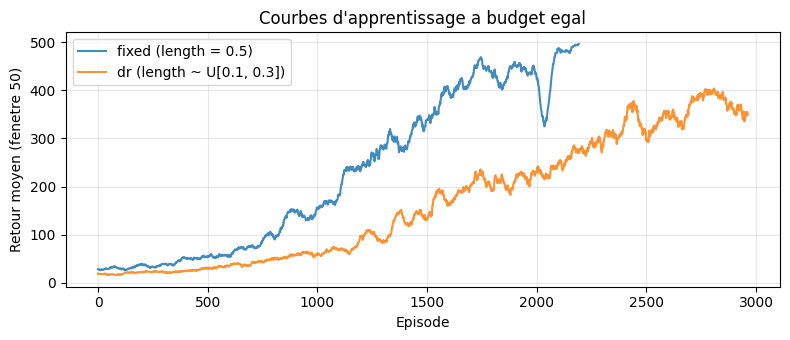

In [7]:
def moving_average(xs, w=50):
    return np.convolve(xs, np.ones(w) / w, mode="valid")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(moving_average(rets_fixed), label="fixed (length = 0.5)", alpha=0.85)
ax.plot(moving_average(rets_dr), label=f"dr (length ~ U[{DR_LENGTH[0]}, {DR_LENGTH[1]}])", alpha=0.85)
ax.set_xlabel("Episode")
ax.set_ylabel("Retour moyen (fenetre 50)")
ax.set_title("Courbes d'apprentissage a budget egal")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


**Lecture des courbes.** Les deux politiques apprennent — la DR ne bloque pas l'apprentissage. Observez *où* chacune plafonne : `fixed` monte haut **dans son monde** ; `dr` apprend une famille de mondes, dont les plus difficiles (perches courtes) plafonnent plus bas — c'est déjà le premier coût, mesuré sur la courbe. La suite mesure si ce coût achète du transfert.

Trois précautions pour lire la figure. La fenêtre glissante de 50 épisodes lisse les courbes : sur la politique `dr`, dont les épisodes sont plus courts, une fenêtre de 50 épisodes couvre une durée simulée plus courte que sur `fixed` — la même fenêtre ne lisse donc pas les deux séries au même degré. La comparaison des *plateaux* est légitime ; celle de la vitesse de montée l'est moins. Enfin, la courbe mesure la performance *pendant* l'entraînement, sur le monde tiré à l'épisode : pour `dr`, la moyenne est donc une moyenne de mondes de difficulté inégale, ce qui explique le plateau plus bas sans rien dire du transfert (section 4).



## 4. Le transfert mesuré

Évaluation **gloutonne** (action argmax) : 20 épisodes par point, mêmes graines pour les deux politiques — la comparaison est appariée.

Le choix de l'action gloutonne simule le déploiement : une politique déployée n'explore pas, elle applique son mode. Il a un effet secondaire utile — l'évaluation devient **déterministe** pour un couple (observation, politique) donné, et la variabilité restante ne vient plus que du tirage de l'état initial. C'est ce qui autorise l'appariement par graines : les deux politiques traversent exactement la même suite d'épisodes, et ce qui les sépare dans le tableau qui suit est bien l'effet de la politique, pas celui du hasard des mondes.


In [8]:
def eval_params(pol: nn.Module, n_ep: int = 20, seed: int = 123, delay: int = 0, **params) -> float:
    """Retour moyen glouton sous des parametres physiques (et une latence) donnes."""
    env = DelayedEnv(make_env(), delay=delay)
    full = dict(NOMINAL)
    full.update(params)
    set_params(env, **full)
    outs = []
    for i in range(n_ep):
        obs, _ = env.reset(seed=seed + i)
        done, tot = False, 0.0
        while not done:
            with torch.no_grad():
                logits, _ = pol(torch.as_tensor(obs, dtype=torch.float32))
            a = int(torch.argmax(logits))
            obs, r, term, trunc, _ = env.step(a)
            tot += r
            done = term or trunc
        outs.append(tot)
    return float(np.mean(outs))

In [9]:
L_GRID = [0.05, 0.075, 0.1, 0.125, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5, 0.7, 1.0, 1.5]

rows_fixed = [eval_params(pol_fixed, length=L) for L in L_GRID]
rows_dr = [eval_params(pol_dr, length=L) for L in L_GRID]

print(f"{'length':>7} | {'fixed':>6} | {'dr':>6} | regime")
print("-" * 40)
for L, rf, rd in zip(L_GRID, rows_fixed, rows_dr):
    regime = ("extrapolation" if L < DR_LENGTH[0]
              else "interpolation (dans la plage DR)" if L <= DR_LENGTH[1]
              else "hors plage DR, cote nominal et au-dela")
    print(f"{L:>7.3f} | {rf:>6.0f} | {rd:>6.0f} | {regime}")

 length |  fixed |     dr | regime
----------------------------------------
  0.050 |     29 |     43 | extrapolation
  0.075 |     88 |    102 | extrapolation
  0.100 |    139 |    186 | interpolation (dans la plage DR)
  0.125 |    203 |    373 | interpolation (dans la plage DR)
  0.150 |    290 |    499 | interpolation (dans la plage DR)
  0.200 |    500 |    494 | interpolation (dans la plage DR)
  0.250 |    500 |    500 | interpolation (dans la plage DR)
  0.300 |    500 |    500 | interpolation (dans la plage DR)
  0.400 |    500 |    495 | hors plage DR, cote nominal et au-dela
  0.500 |    500 |    495 | hors plage DR, cote nominal et au-dela
  0.700 |    500 |    496 | hors plage DR, cote nominal et au-dela
  1.000 |    500 |    492 | hors plage DR, cote nominal et au-dela
  1.500 |    500 |    499 | hors plage DR, cote nominal et au-dela


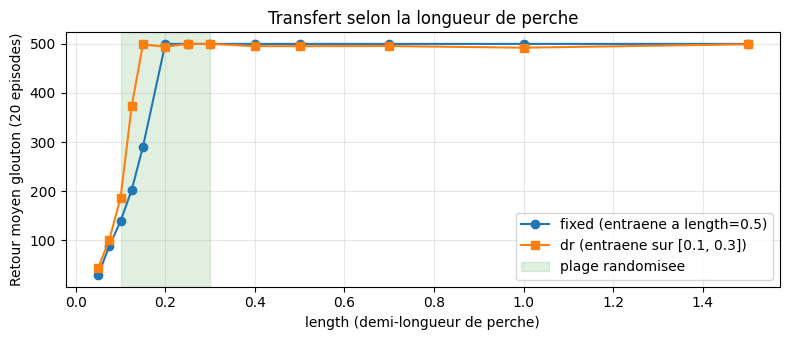

In [10]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(L_GRID, rows_fixed, "o-", label="fixed (entraene a length=0.5)")
ax.plot(L_GRID, rows_dr, "s-", label=f"dr (entraene sur [{DR_LENGTH[0]}, {DR_LENGTH[1]}])")
ax.axvspan(DR_LENGTH[0], DR_LENGTH[1], alpha=0.12, color="green", label="plage randomisee")
ax.set_xlabel("length (demi-longueur de perche)")
ax.set_ylabel("Retour moyen glouton (20 episodes)")
ax.set_title("Transfert selon la longueur de perche")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

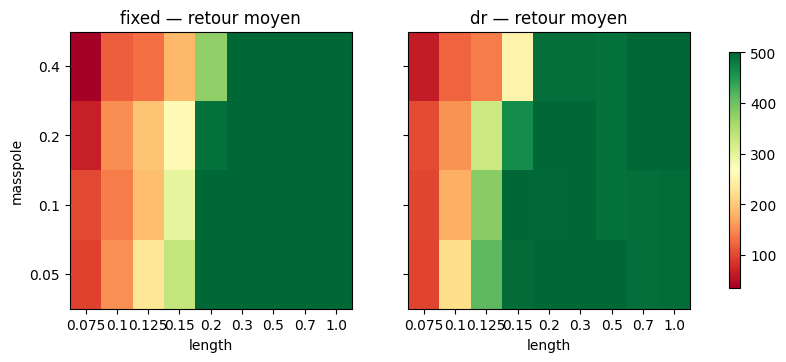

In [11]:
# Grille heatmap complete : retour en fonction de length x masspole
L_AX = [0.075, 0.1, 0.125, 0.15, 0.2, 0.3, 0.5, 0.7, 1.0]
M_AX = [0.05, 0.1, 0.2, 0.4]

def heat(pol):
    return np.array([[eval_params(pol, length=L, masspole=M, n_ep=10)
                      for L in L_AX] for M in M_AX])

H_fixed, H_dr = heat(pol_fixed), heat(pol_dr)
vmin = min(H_fixed.min(), H_dr.min())

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, H, name in ((axes[0], H_fixed, "fixed"), (axes[1], H_dr, "dr")):
    im = ax.imshow(H, origin="lower", aspect="auto", vmin=vmin, vmax=500, cmap="RdYlGn")
    ax.set_xticks(range(len(L_AX)), [str(x) for x in L_AX])
    ax.set_yticks(range(len(M_AX)), [str(m) for m in M_AX])
    ax.set_xlabel("length")
    ax.set_title(f"{name} — retour moyen")
axes[0].set_ylabel("masspole")
fig.colorbar(im, ax=axes, shrink=0.85)
plt.show()


### Lecture de la carte de chaleur

La carte croise deux axes : en abscisse la demi-longueur de perche (neuf valeurs de 0,075 à 1,0), en ordonnée la masse de la perche (0,05 à 0,4) ; chaque case donne le retour moyen glouton pour ce couple. Les deux panneaux — `fixed` à gauche, `dr` à droite — partagent **la même échelle de couleurs** (borne basse commune aux deux matrices, borne haute 500), ce qui est la condition pour comparer deux politiques : une échelle par panneau ferait voir un dégradé là où il n'y a qu'une différence de calibrage.

Trois questions valent la lecture, dans cet ordre.

1. **Où est la frontière d'effondrement de chaque politique ?** Elle doit retrouver le profil mesuré par le tableau de transfert — et si elle ne le retrouve pas, c'est un vrai résultat, pas un bug : la carte ajoute une dimension, et une dimension peut déplacer la frontière.
2. **La masse de la perche déplace-t-elle cette frontière ?** Si un couple (ℓ, m) s'effondre alors que le même ℓ tient pour une masse voisine, alors la difficulté n'est pas séparable — et une DR qui ne randomise qu'un seul axe laisse un second angle mort, dépendant de la difficulté. C'est exactement la question que le §5 pose sur la gravité, transposée sur la masse.
3. **La case est-elle saturée ?** Une case à 500 signifie « parfait », pas « bon » : sur les longues perches, les deux politiques saturent, et la carte ne distingue plus rien. La lecture utile se fait donc dans la zone où les scores **descendent**, pas dans celle où ils sont au plafond.

Cette carte est aussi la mesure la plus coûteuse du carnet : 9 × 4 couples, 10 épisodes par case, pour les deux politiques — soit 720 évaluations gloutonnes, contre 13 × 20 × 2 pour le tableau de transfert. La précision d'un point (ℓ, m) est donc deux fois moindre que sur un point de la grille : c'est le prix de la vision à deux dimensions, et la raison de ne pas lire une case isolée comme une mesure.



## 5. Ce que la randomisation ne couvre pas

La DR rend robuste **aux dimensions randomisées** — en théorie, et seulement elles. Les dimensions jamais randomisées restent nues : c'est l'aveugle structurel de la méthode, et l'argument pour élargir la famille (ou pour l'identification de système quand une dimension critique est connue). Mesurons trois dimensions physiques jamais vues à l'entraînement (gravité, masse de perche, force moteur), puis la latence d'action.

Le choix des axes aveugles est lui-même un choix d'expérience, et il mérite d'être justifié. Gravité, masse de perche et force moteur ont été retenues **parce qu'elles ne sont pas le paramètre discriminant** de `CartPole` : le chariot est déjà assez massif, la perche assez légère, le moteur assez puissant pour que le système reste contrôlable sur ces axes. Un axe sur lequel aucune politique ne tombe n'enseigne rien sur la robustesse ; il enseigne sur la **marge de sécurité** de la tâche, et il faut le savoir pour ne pas confondre les deux.

La latence est d'une autre nature : ce n'est pas un paramètre physique mais une propriété **dynamique** du dispositif (le bus de commande). Une plage de valeurs physiques ne la décrit pas — c'est pourquoi elle se mesure à part.


In [12]:
print("Dimensions jamais randomisees a l'entrainement (gravite, masse de perche, force moteur) :")
for name, sweep in (("gravity", [6.0, 9.8, 15.0, 20.0]),
                    ("masspole", [0.05, 0.1, 0.3, 0.6]),
                    ("force_mag", [5.0, 10.0, 18.0, 25.0])):
    fx = [round(eval_params(pol_fixed, **{name: v})) for v in sweep]
    dr = [round(eval_params(pol_dr, **{name: v})) for v in sweep]
    print(f"  {name:>10} : fixed {fx} | dr {dr}  (sweep {sweep})")

print()
print("Latence d'action (jamais randomisee non plus) :")
fx = [round(eval_params(pol_fixed, delay=d)) for d in (0, 1, 2, 3)]
dr = [round(eval_params(pol_dr, delay=d)) for d in (0, 1, 2, 3)]
print(f"  delay 0-3 : fixed {fx} | dr {dr}")

Dimensions jamais randomisees a l'entrainement (gravite, masse de perche, force moteur) :


     gravity : fixed [500, 500, 500, 500] | dr [500, 495, 497, 498]  (sweep [6.0, 9.8, 15.0, 20.0])


    masspole : fixed [500, 500, 498, 500] | dr [496, 495, 496, 496]  (sweep [0.05, 0.1, 0.3, 0.6])


   force_mag : fixed [500, 500, 500, 500] | dr [498, 495, 498, 500]  (sweep [5.0, 10.0, 18.0, 25.0])

Latence d'action (jamais randomisee non plus) :


  delay 0-3 : fixed [500, 500, 500, 325] | dr [495, 494, 495, 488]



### Interprétation

Les blocs de mesures ci-dessus (courbes d'apprentissage, tableau et courbe de transfert, carte de chaleur, dimensions non randomisées) se lisent ensemble :

1. **Ce que la DR achète** : sur la grille de transfert, l'écart le plus grand vit dans la plage randomisée elle-même. Au point `length = 0.15`, la politique `fixed` s'effondre (~290) là où la politique `dr` est quasi parfaite (~499) — c'est l'interpolation, la promesse tenue de la méthode. Et hors de la plage, côté nominal et perches longues, `dr` ne perd rien (~495 partout) : la robustesse n'a pas sacrifié le régime nominal.

2. **Ce qu'elle coûte** : sur les courbes d'apprentissage, la fenêtre glissante de `dr` plafonne plus bas (~350 contre ~496) — elle apprend une famille de mondes dont les plus durs pèsent sur la moyenne. La robustesse n'est pas gratuite : à budget égal, elle se paie en plafond apparent pendant l'entraînement, racheté au moment du transfert.

3. **La surprise mesurée** : la latence d'action n'a **jamais** été randomisée, et pourtant à `delay = 3` la politique `fixed` s'effondre (~325) quand `dr` tient (~490). Randomiser les perches courtes a forcé des corrections serrées — une compétence qui transfère à la latence. La robustesse peut **déborder** de la dimension randomisée ; c'est un argument empirique pour randomiser les régimes *difficiles* plutôt que beaucoup de dimensions faciles.

4. **Ce qu'elle ne couvre pas** : les dimensions physiques jamais randomisées (gravité, masse, force) restent à ~500 pour les deux politiques — `CartPole` a là de la **marge de sécurité** : la tâche transfère toute seule sur ces axes, et l'absence d'effondrement n'y prouve rien. C'est la mise en garde de ce carnet : *sur un axe à large marge, aucune politique ne tombe, DR ou pas*.

5. **La limite honnête** : sous la plage randomisée (`length < 0.1`), aucune des deux politiques n'a de garantie — extrapoler reste un pari, arbitré par la largeur de plage choisie. Le tableau précise *comment* chacune s'effondre. `fixed` passe de 500 (à ℓ = 0,2) à 290, puis 139, puis 88, puis 29 : une chute de seuil, non une dégradation progressive — il n'y a pas de marge entre « son » monde et le monde voisin. `dr` tient 373 à ℓ = 0,125 et tient encore plus haut que `fixed` sur tout l'axe extrapolé (186 contre 139 à 0,1 ; 102 contre 88 à 0,075 ; 43 contre 29 à 0,05) : la famille randomisée ne protège pas hors de la famille, elle y dégrade avec plus de douceur — et l'écart se resserre à mesure qu'on s'éloigne.

**Ce que cette mesure ne prouve pas.** Trois limites, à connaître avant de lire ces chiffres comme une preuve générale.

- **Une seule graine.** Les deux entraînements utilisent `seed = 0` et l'évaluation `seed = 123`. L'écart mesuré entre les deux politiques — plusieurs centaines de points — est très supérieur au bruit de tirage qu'on observerait en changeant de graine ; les écarts fins, eux, ne sont pas interprétables.
- **Une seule tâche, une seule famille.** `CartPole` est un système linéaire, sans frottement, sans observation partielle : la conclusion « randomiser le régime difficile » est démontrée sur une tâche où la seule difficulté est la longueur de perche.
- **Un métrique saturé.** Le retour maximal de `CartPole-v1` vaut 500 (épisode tronqué à 500 pas). Toute valeur à 500 signifie « parfait », pas « bon » : au-delà de ℓ = 0,2, les deux politiques sont parfaites, et la comparaison n'a plus de résolution. Les écarts de quelques points en haut de tableau (495 contre 500) sont deux scores saturés, pas deux niveaux de qualité.



## 6. Exercices

Trois exercices, du plus mécanique au plus conceptuel. Les stubs s'exécutent sans erreur (convention C.1) : chaque fonction retourne `None` tant qu'elle n'est pas complétée, et la cellule de test saute gracieusement.

Les trois exercices ne sont pas trois variantes d'un même geste : chacun reprend une section du carnet et en déplace l'usage.

1. **Exercice 1 — curriculum d'élargissement** (§2, politique). Au lieu de tirer dans la plage DR complète dès le départ, on part du nominal (ℓ = 0,5) et on descend vers les perches courtes à mesure que la politique progresse. C'est la version manuelle de l'ADR mentionnée en §7 : élargir les plages au fil de l'entraînement. L'exercice rend visible le compromis que l'ADR cache — élargir tôt coûte (la politique n'a pas encore les compétences), élargir tard coûte (la politique s'est spécialisée pour un monde qu'on quitte). Il faut de plus garantir le cas `progress = 0` : la fonction doit rester valide au point nominal pur.
2. **Exercice 2 — rapport zero-shot** (§4, transfert). La forme du livrable de déploiement : sur une liste de mondes, rendre un score par monde, sans adaptation. C'est le tableau de bord d'un déploiement sim-to-real — il ne dit pas « la politique est bonne », il dit « elle est bonne *là* ». L'ordre des scores rendus doit suivre l'ordre de la liste d'entrée : le rapport sert à comparer deux exécutions, donc à être positionnable.
3. **Exercice 3 — matrice d'aveugle** (§5, ce que la DR ne couvre pas). Croiser un axe jamais randomisé (gravité) avec l'axe randomisé (longueur), et regarder si l'effet de l'un dépend de l'autre. C'est la question qu'un axe à marge de sécurité ne peut pas trancher : si l'effet de la gravité est nul *parce que* la tâche est facile, il le restera partout ; s'il n'est nul qu'aux longues perches, alors la gravité est un second angle mort, dépendant de la difficulté.

Deux consignes de forme, qui valent pour tous les carnets de la série : chaque cellule de lecture doit commenter **une** sortie précise et ne rien redire d'une autre ; et une correction qui change une sortie se ré-exécute, elle ne se réécrit pas à la main.


In [13]:
def curriculum_params(progress: float, rng: np.random.Generator) -> dict | None:
    """Exercice 1 -- curriculum d'elargissement.

    Au lieu de randomiser sur la plage pleine des le depart, elargir progressivement :
    progress in [0, 1], plage effective = [0.5 - 0.4*progress, 0.5 + 0.2*progress]
    (on part du nominal 0.5 et on descend vers les perches courtes au fur et a mesure).
    Renvoie le dict de parametres {'length': ...} tire uniformement dans la plage effective.

    # TODO Etape 1 : calculer bornes = (0.5 - 0.4 * progress, 0.5 + 0.2 * progress)
    # TODO Etape 2 : tirer length uniformement entre les bornes avec rng.uniform
    # Indice : la fonction doit rester valide pour progress = 0 (nominal pur).
    """
    # Exercice a completer
    return None

In [14]:
def zero_shot_report(pol: nn.Module, worlds: list[dict], n_ep: int = 20) -> list[float] | None:
    """Exercice 2 -- rapport zero-shot sur des mondes surpris.

    worlds = liste de dicts de parametres physiques (ex. [{'length': 0.08}, {'gravity': 15.0}]).
    Renvoie la liste des retours moyens gloutons, un par monde, dans l'ordre.

    # TODO Etape 1 : pour chaque monde w de worlds, appeler eval_params(pol, n_ep=n_ep, **w)
    # TODO Etape 2 : collecter les retours dans une liste et la renvoyer
    # Indice : eval_params accepte les parametres physiques en mots-cles.
    """
    # Exercice a completer
    return None

In [15]:
def blind_spot_matrix(pol: nn.Module, gravity_values: list[float]) -> dict | None:
    """Exercice 3 -- cartographier l'aveugle de la randomisation.

    La gravite n'a JAMAIS ete randomisee a l'entrainement. Cartographier son effet
    croise avec la longueur : pour chaque g de gravity_values, evaluer le retour a
    length=0.15, 0.3 et 0.5. Renvoyer {g: [r_0.15, r_0.3, r_0.5]}.

    # TODO Etape 1 : boucle sur gravity_values
    # TODO Etape 2 : pour chaque g, evaluer les trois longueurs via eval_params(pol, gravity=g, length=L)
    # Indice : la question interessante est si l'effet de g depend de la longueur.
    """
    # Exercice a completer
    return None

In [16]:
# Tests gracieux des exercices (sautes tant que non completes)
r1 = curriculum_params(0.5, np.random.default_rng(0))
if r1 is None:
    print("Exercice 1 non complete -- saut (retour None)")
else:
    ok = DR_LENGTH[0] - 0.45 <= r1["length"] <= 0.75
    print(f"Exercice 1 : length = {r1['length']:.3f} -> {'OK' if ok else 'hors bornes attendues'}")

r2 = zero_shot_report(pol_fixed, [{"length": 0.15}, {"gravity": 15.0}], n_ep=5)
if r2 is None:
    print("Exercice 2 non complete -- saut (retour None)")
else:
    print(f"Exercice 2 : retours zero-shot = {[round(x) for x in r2]}")

r3 = blind_spot_matrix(pol_dr, [6.0, 9.8, 15.0])
if r3 is None:
    print("Exercice 3 non complete -- saut (retour None)")
else:
    print(f"Exercice 3 : matrice = {r3}")

Exercice 1 non complete -- saut (retour None)
Exercice 2 non complete -- saut (retour None)
Exercice 3 non complete -- saut (retour None)



## 7. Limites et où aller ensuite

**Ce que ce carnet ne couvre pas** :

- la **randomisation visuelle** de Tobin et al. 2017 (textures, lumières, caméras — l'autre moitié de la méthode, décisive pour la manipulation depuis pixels) ;
- la DR sur les **observations** (bruit de capteur) et les **récompenses** ;
- l'alternative symétrique : l'**identification de système** (estimer les paramètres réels, ajuster le simulateur) et le compromis entre les deux écoles ;
- les résultats à grande échelle : la main robotique d'OpenAI (OpenAI et al., 2019) a transféré en réel grâce à l'**ADR** (*automatic domain randomization*), qui élargit automatiquement au fil de l'entraînement les plages des paramètres physiques et visuels randomisés — la version industrielle du principe mesuré ici sur un chariot.

**Ce qu'une chaîne sim-to-real réelle ajoute.** La DR n'est qu'une brique d'un dispositif plus large, et ce carnet mesure cette brique seule. En pratique, on lui ajoute deux choses. D'abord l'**identification**, quand un paramètre critique est mesurable : on resserre la famille DR autour d'une estimation (une masse de charge relevée sur le robot, par exemple), ce qui réduit le prix d'apprentissage — c'est le compromis entre les deux écoles énoncé plus haut, et non une alternative exclusive. Ensuite le **finage-tuning sur le système réel** : un stage de correction, bref et risqué (le vrai système peut se casser), qui amortit ce que la simulation ne pouvait pas dire. L'ADR citée ci-dessus est l'autre moitié du travail : transformer la famille randomisée en objet que le learner pilote, au lieu d'une plage fixée à la main une fois pour toutes.

**Ce que la comparaison apprend sur la méthode, pas sur le chariot.** Les deux politiques ont reçu le même nombre de pas et le même nombre de mises à jour ; la seule différence est la distribution des mondes vues. Tout l'écart mesuré — le plafond plus bas à l'entraînement, l'effondrement évité dans la famille, le débordement inattendu sur la latence — est donc imputable à cette différence, et à rien d'autre. C'est ce qui fait de ce carnet une **mesure du coût de la randomisation**, plutôt qu'une démonstration du chariot à perche.

**Références** : Tobin, Fong, Ray et al., *Domain Randomization for Transferring Deep Neural Networks from Simulation to the Real World* (arXiv:1703.06907, 2017) · Peng, Andrychowicz et al., *Sim-to-Real Transfer of Robotic Control with Dynamics Randomization* (arXiv:1710.06537, 2018) · OpenAI et al., *Solving Rubik's Cube with a Robot Hand* (arXiv:1910.07113, 2019).

**Navigation série** : [RL-19 Reward Tampering](RL-19-Reward-Tampering-Python.ipynb) — suivant : [RL-21 Auto-Jeu AlphaZero](RL-21-Auto-Jeu-AlphaZero-Python.ipynb) — [README de la série](README.md)
